# Examen del módulo 2 - métodos de regresión

**Estudiante:** Julian Emiliano Ortiz Rivero  
**Materia:** Aprendizaje Supervisado  
**Problema:** estabilidad de redes eléctricas

Este cuaderno compara cinco familias de regresión con el mismo protocolo de validación cruzada. El
archivo de prueba se usa únicamente al final, cuando esté disponible.

In [1]:
NOMBRE = "Julian Emiliano Ortiz Rivero"

import sys
from pathlib import Path
import time
import warnings

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import Markdown, display
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

print("Nombre:", NOMBRE)
print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("Matplotlib:", matplotlib.__version__)
print("scikit-learn:", sklearn.__version__)

Nombre: Julian Emiliano Ortiz Rivero
Python: 3.12.14
NumPy: 2.3.5
pandas: 3.0.1
Matplotlib: 3.11.2
scikit-learn: 1.9.1


## 1. Carga y revisión inicial

Se verifica la forma del archivo, los tipos de datos, los valores faltantes y los registros
duplicados antes de ajustar cualquier modelo.

In [2]:
RUTA_ENTRENAMIENTO = Path("electrical_grid_stability_train.csv")
if not RUTA_ENTRENAMIENTO.exists():
    raise FileNotFoundError("Coloca electrical_grid_stability_train.csv junto al notebook")

datos = pd.read_csv(RUTA_ENTRENAMIENTO)
esperadas = [f"tau{i}" for i in range(1, 5)] + [f"p{i}" for i in range(1, 5)] + [f"g{i}" for i in range(1, 5)] + ["stab"]
if list(datos.columns) != esperadas:
    raise ValueError(f"Columnas inesperadas: {list(datos.columns)}")

print("Dimensiones:", datos.shape)
print("Duplicados:", int(datos.duplicated().sum()))
print("Valores faltantes:", int(datos.isna().sum().sum()))
display(datos.head())
display(datos.describe().T.round(4))

Dimensiones: (8000, 13)
Duplicados: 0
Valores faltantes: 0


,tau1,tau2,tau3,tau4,p1,p2,p3,p4,g1,g2,g3,g4,stab
0,2.959060,3.079885,8.381025,9.780754,3.763085,-0.782604,-1.257395,-1.723086,0.650456,0.859578,0.887445,0.958034,0.055347
1,9.304097,4.902524,3.047541,1.369357,5.067812,-1.940058,-1.872742,-1.255012,0.413441,0.862414,0.562139,0.781760,-0.005957
2,8.971707,8.848428,3.046479,1.214518,3.405158,-1.207456,-1.277210,-0.920492,0.163041,0.766689,0.839444,0.109853,0.003471
3,0.716415,7.669600,4.486641,2.340563,3.963791,-1.027473,-1.938944,-0.997374,0.446209,0.976744,0.929381,0.362718,0.028871
4,6.999209,9.109247,3.784066,4.267788,4.429669,-1.857139,-0.670397,-1.902133,0.261793,0.077930,0.542884,0.469931,-0.017385


,count,mean,std,min,25%,50%,75%,max
tau1,8000.0,5.2359,2.7361,0.5008,2.8668,5.2261,7.5978,9.9995
tau2,8000.0,5.2423,2.7528,0.5001,2.8437,5.2511,7.6317,9.9998
tau3,8000.0,5.2534,2.7422,0.5008,2.8849,5.2490,7.6268,9.9995
tau4,8000.0,5.2443,2.7556,0.5016,2.8550,5.2461,7.6185,9.9994
p1,8000.0,3.7512,0.7559,1.5826,3.2164,3.7483,4.2885,5.8273
p2,8000.0,-1.2501,0.4312,-1.9999,-1.6237,-1.2467,-0.8794,-0.5001
p3,8000.0,-1.2508,0.4327,-1.9999,-1.6240,-1.2533,-0.8764,-0.5001
p4,8000.0,-1.2503,0.4328,-1.9999,-1.6263,-1.2482,-0.8767,-0.5000
g1,8000.0,0.5220,0.2742,0.0500,0.2833,0.5203,0.7579,0.9999
g2,8000.0,0.5232,0.2750,0.0501,0.2841,0.5219,0.7612,0.9999


## 2. Análisis exploratorio

Las distribuciones permiten revisar rangos y posibles valores extremos. La matriz de correlación
muestra la relación lineal entre los predictores y `stab`.

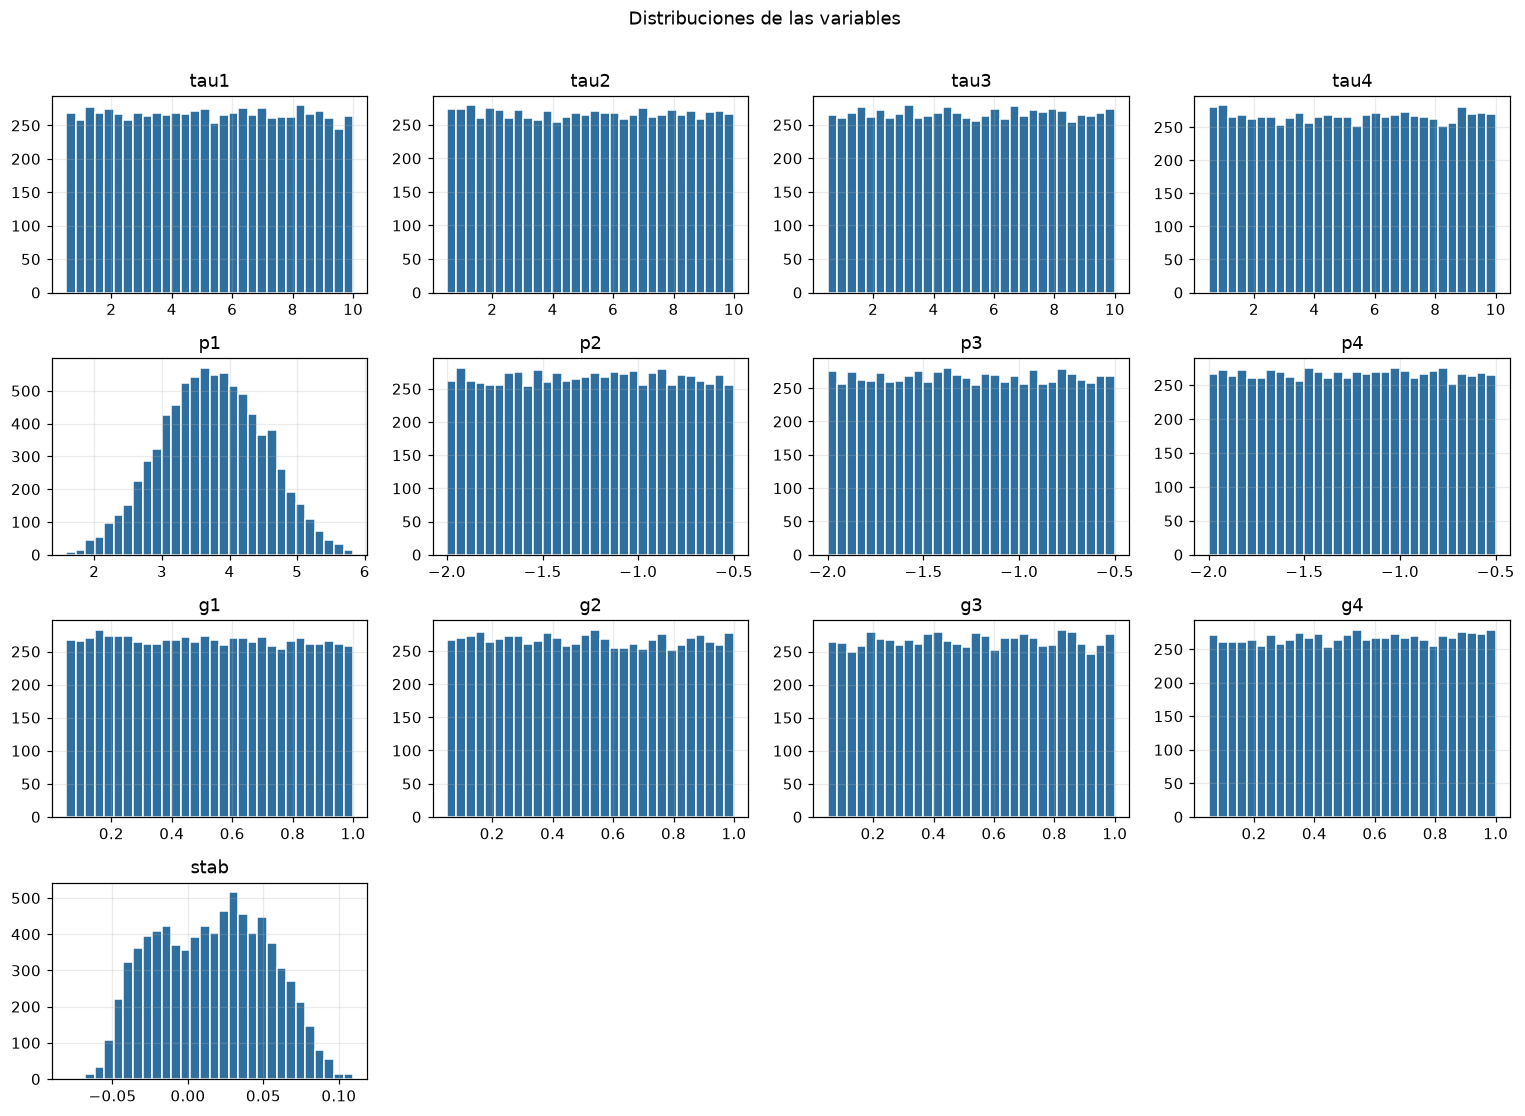

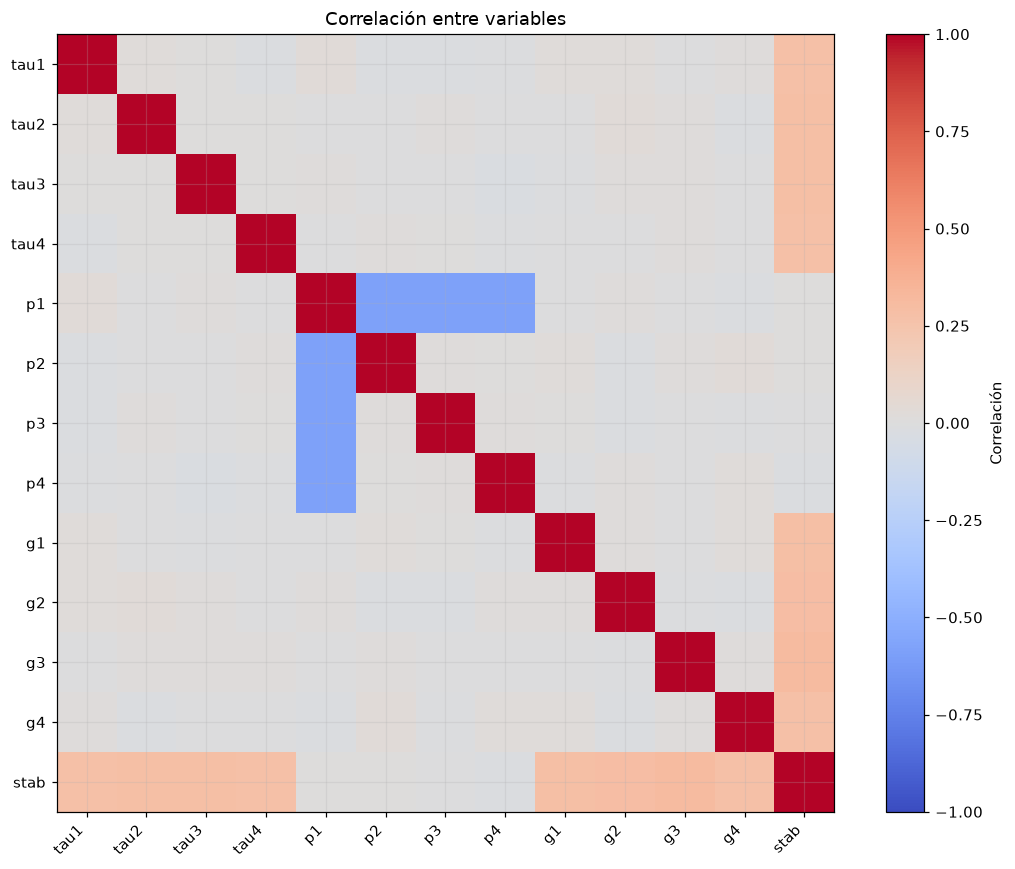

Correlación con stab:


,correlacion
p4,-0.0162
p3,-0.0025
p2,0.0055
p1,0.0076
tau1,0.2771
g4,0.2779
tau4,0.2804
tau3,0.2824
g1,0.2834
tau2,0.2860


In [3]:
ejes = datos.hist(bins=30, figsize=(14, 10), color="#2f6f9f", edgecolor="white")
plt.suptitle("Distribuciones de las variables", y=1.01)
plt.tight_layout()
plt.show()

correlacion = datos.corr(numeric_only=True)
plt.figure(figsize=(10, 8))
imagen = plt.imshow(correlacion, cmap="coolwarm", vmin=-1, vmax=1)
plt.xticks(range(len(correlacion.columns)), correlacion.columns, rotation=45, ha="right")
plt.yticks(range(len(correlacion.index)), correlacion.index)
plt.colorbar(imagen, label="Correlación")
plt.title("Correlación entre variables")
plt.tight_layout()
plt.show()

print("Correlación con stab:")
display(correlacion["stab"].drop("stab").sort_values().to_frame("correlacion").round(4))

In [4]:
q1 = datos.quantile(0.25)
q3 = datos.quantile(0.75)
iqr = q3 - q1
atipicos = datos.lt(q1 - 1.5 * iqr) | datos.gt(q3 + 1.5 * iqr)
resumen_atipicos = atipicos.sum().to_frame("cantidad")
resumen_atipicos["porcentaje"] = (100 * resumen_atipicos["cantidad"] / len(datos)).round(3)
display(resumen_atipicos)

error_balance = (datos["p1"] + datos["p2"] + datos["p3"] + datos["p4"]).abs().max()
print(f"Mayor error en el balance p1 + p2 + p3 + p4: {error_balance:.2e}")

,cantidad,porcentaje
tau1,0,0.000
tau2,0,0.000
tau3,0,0.000
tau4,0,0.000
p1,1,0.012
p2,0,0.000
p3,0,0.000
p4,0,0.000
g1,0,0.000
g2,0,0.000


Mayor error en el balance p1 + p2 + p3 + p4: 1.00e-09


### Hallazgos del EDA

- El archivo contiene 8 000 observaciones y 13 columnas numéricas.
- No hay valores faltantes ni registros duplicados.
- La regla del IQR marca un solo valor de `p1`. Su proporción es 0.013 % y se conserva porque está
  dentro del comportamiento esperado de la potencia total.
- `tau1` a `tau4` y `g1` a `g4` presentan las asociaciones lineales más claras con `stab`. Las
  correlaciones individuales son moderadas, entre 0.277 y 0.309.
- `p1` depende de `p2`, `p3` y `p4` por el balance de la red. Se conservan las columnas solicitadas,
  aunque esta relación puede volver inestables los coeficientes de una regresión sin regularización.

No se eliminan observaciones. El escalamiento se coloca dentro de los `Pipeline` que lo necesitan
para evitar fuga de información durante la validación cruzada.

## 3. Preparación y protocolo de evaluación

Se usan cinco pliegues con mezcla y una semilla fija. Todos los modelos reciben las mismas
particiones. La métrica principal es RMSE. También se reporta R² para facilitar la interpretación.

In [5]:
X = datos.drop(columns="stab")
y = datos["stab"]

cv = KFold(n_splits=5, shuffle=True, random_state=42)
metricas = {"rmse": "neg_root_mean_squared_error", "r2": "r2"}
resultados = []
modelos_finales = {}


def registrar(nombre, estimador, rmse_pliegues, r2_pliegues, parametros):
    resultados.append(
        {
            "modelo": nombre,
            "rmse_medio": float(np.mean(rmse_pliegues)),
            "rmse_desviacion": float(np.std(rmse_pliegues)),
            "r2_medio": float(np.mean(r2_pliegues)),
            "r2_desviacion": float(np.std(r2_pliegues)),
            "hiperparametros": str(parametros),
        }
    )
    modelos_finales[nombre] = estimador


def registrar_busqueda(nombre, busqueda):
    i = busqueda.best_index_
    rmse_medio = -busqueda.cv_results_["mean_test_rmse"][i]
    rmse_desviacion = busqueda.cv_results_["std_test_rmse"][i]
    r2_medio = busqueda.cv_results_["mean_test_r2"][i]
    r2_desviacion = busqueda.cv_results_["std_test_r2"][i]
    registrar(
        nombre,
        busqueda.best_estimator_,
        np.array([rmse_medio]),
        np.array([r2_medio]),
        busqueda.best_params_,
    )
    resultados[-1]["rmse_desviacion"] = float(rmse_desviacion)
    resultados[-1]["r2_desviacion"] = float(r2_desviacion)

## 4. Regresión lineal

El modelo lineal funciona como referencia. Se escalan los predictores dentro del pipeline.

In [6]:
lineal = Pipeline(
    [
        ("escalado", StandardScaler()),
        ("modelo", LinearRegression()),
    ]
)
t0 = time.time()
cv_lineal = cross_validate(lineal, X, y, cv=cv, scoring=metricas, n_jobs=1)
lineal.fit(X, y)
registrar(
    "Regresión lineal",
    lineal,
    -cv_lineal["test_rmse"],
    cv_lineal["test_r2"],
    {},
)
print(f"Tiempo: {time.time() - t0:.1f} s")
print(resultados[-1])

Tiempo: 0.1 s
{'modelo': 'Regresión lineal', 'rmse_medio': 0.02208792738002177, 'rmse_desviacion': 0.0004734254636584551, 'r2_medio': 0.6421992552480669, 'r2_desviacion': 0.017596544838727263, 'hiperparametros': '{}'}


## 5. Regresión polinomial sin regularización

Se comparan grados 2 y 3. La selección se realiza únicamente con los pliegues de entrenamiento.

In [7]:
polinomial = Pipeline(
    [
        ("polinomio", PolynomialFeatures(include_bias=False)),
        ("escalado", StandardScaler()),
        ("modelo", LinearRegression()),
    ]
)
malla_polinomial = {"polinomio__degree": [2, 3]}
t0 = time.time()
busqueda_polinomial = GridSearchCV(
    polinomial,
    malla_polinomial,
    cv=cv,
    scoring=metricas,
    refit="rmse",
    n_jobs=1,
)
busqueda_polinomial.fit(X, y)
registrar_busqueda("Polinomial sin regularización", busqueda_polinomial)
print(f"Tiempo: {time.time() - t0:.1f} s")
print("Mejor configuración:", busqueda_polinomial.best_params_)
print(resultados[-1])

Tiempo: 3.5 s
Mejor configuración: {'polinomio__degree': 3}
{'modelo': 'Polinomial sin regularización', 'rmse_medio': 0.00871972157279945, 'rmse_desviacion': 0.0001675961443747691, 'r2_medio': 0.9442275095893938, 'r2_desviacion': 0.0028588142467316185, 'hiperparametros': "{'polinomio__degree': 3}"}


## 6. Regresión polinomial con regularización

Se utiliza Ridge sobre un polinomio de grado 2. La malla compara cinco intensidades de penalización.

In [8]:
ridge = Pipeline(
    [
        ("polinomio", PolynomialFeatures(degree=2, include_bias=False)),
        ("escalado", StandardScaler()),
        ("modelo", Ridge()),
    ]
)
malla_ridge = {"modelo__alpha": [0.01, 0.1, 1.0, 10.0, 100.0]}
t0 = time.time()
busqueda_ridge = GridSearchCV(
    ridge,
    malla_ridge,
    cv=cv,
    scoring=metricas,
    refit="rmse",
    n_jobs=1,
)
busqueda_ridge.fit(X, y)
registrar_busqueda("Polinomial con Ridge", busqueda_ridge)
print(f"Tiempo: {time.time() - t0:.1f} s")
print("Mejor configuración:", busqueda_ridge.best_params_)
print(resultados[-1])

Tiempo: 0.8 s
Mejor configuración: {'modelo__alpha': 1.0}
{'modelo': 'Polinomial con Ridge', 'rmse_medio': 0.012335889058405596, 'rmse_desviacion': 0.0001231531549896801, 'r2_medio': 0.8884147372764912, 'r2_desviacion': 0.004079327847277348, 'hiperparametros': "{'modelo__alpha': 1.0}"}


## 7. Support Vector Regression

Se prueba el kernel RBF. La búsqueda ajusta `C`, `epsilon` y `gamma`. El escalamiento forma parte del
pipeline porque SVR depende de las distancias entre observaciones.

In [9]:
svr = Pipeline(
    [
        ("escalado", StandardScaler()),
        ("modelo", SVR(kernel="rbf")),
    ]
)
malla_svr = {
    "modelo__C": [1.0, 10.0, 100.0],
    "modelo__epsilon": [0.01, 0.1],
    "modelo__gamma": ["scale", 0.01],
}
t0 = time.time()
busqueda_svr = GridSearchCV(
    svr,
    malla_svr,
    cv=cv,
    scoring=metricas,
    refit="rmse",
    n_jobs=1,
)
busqueda_svr.fit(X, y)
registrar_busqueda("SVR con RBF", busqueda_svr)
print(f"Tiempo: {time.time() - t0:.1f} s")
print("Mejor configuración:", busqueda_svr.best_params_)
print(resultados[-1])

Tiempo: 250.8 s
Mejor configuración: {'modelo__C': 10.0, 'modelo__epsilon': 0.01, 'modelo__gamma': 0.01}
{'modelo': 'SVR con RBF', 'rmse_medio': 0.008847463031206737, 'rmse_desviacion': 0.00016486200400890169, 'r2_medio': 0.9425941443414965, 'r2_desviacion': 0.0026605196715778824, 'hiperparametros': "{'modelo__C': 10.0, 'modelo__epsilon': 0.01, 'modelo__gamma': 0.01}"}


## 8. Árbol de decisión

La profundidad, el tamaño mínimo de hoja y el parámetro de poda se ajustan mediante la misma
validación cruzada. No se escala porque el árbol trabaja con ordenamientos y puntos de corte.

In [10]:
arbol = DecisionTreeRegressor(random_state=42)
malla_arbol = {
    "max_depth": [3, 5, 8, 12, None],
    "min_samples_leaf": [1, 5, 20],
    "ccp_alpha": [0.0, 0.000001, 0.00001],
}
t0 = time.time()
busqueda_arbol = GridSearchCV(
    arbol,
    malla_arbol,
    cv=cv,
    scoring=metricas,
    refit="rmse",
    n_jobs=1,
)
busqueda_arbol.fit(X, y)
registrar_busqueda("Árbol de decisión", busqueda_arbol)
print(f"Tiempo: {time.time() - t0:.1f} s")
print("Mejor configuración:", busqueda_arbol.best_params_)
print(resultados[-1])

Tiempo: 14.9 s
Mejor configuración: {'ccp_alpha': 0.0, 'max_depth': None, 'min_samples_leaf': 20}
{'modelo': 'Árbol de decisión', 'rmse_medio': 0.018743392959073773, 'rmse_desviacion': 0.00042604569740757267, 'r2_medio': 0.7421748124851321, 'r2_desviacion': 0.016222352216330813, 'hiperparametros': "{'ccp_alpha': 0.0, 'max_depth': None, 'min_samples_leaf': 20}"}


## 9. Comparación de resultados

La tabla usa la media y la desviación estándar obtenidas en los cinco pliegues. Un RMSE menor indica
predicciones más cercanas al valor real de `stab`.

In [11]:
tabla_resultados = pd.DataFrame(resultados).sort_values("rmse_medio").reset_index(drop=True)
columnas_numericas = ["rmse_medio", "rmse_desviacion", "r2_medio", "r2_desviacion"]
tabla_mostrada = tabla_resultados.copy()
tabla_mostrada[columnas_numericas] = tabla_mostrada[columnas_numericas].round(6)
display(tabla_mostrada)

mejor = tabla_resultados.iloc[0]
segundo = tabla_resultados.iloc[1]
diferencia = segundo["rmse_medio"] - mejor["rmse_medio"]
conclusion = f'''
### Conclusiones

El menor RMSE de validación corresponde a **{mejor['modelo']}**, con
**{mejor['rmse_medio']:.6f} ± {mejor['rmse_desviacion']:.6f}**. El segundo lugar es
**{segundo['modelo']}** con una diferencia de **{diferencia:.6f}**. La comparación se hizo con las
mismas cinco particiones para todos los modelos. La regresión lineal sirve como referencia, mientras
los métodos no lineales pueden representar interacciones entre tiempos de reacción, potencias y
elasticidades. La decisión final se basa en validación cruzada porque el archivo de prueba no debe
participar en la selección.
'''
display(Markdown(conclusion))

,modelo,rmse_medio,rmse_desviacion,r2_medio,r2_desviacion,hiperparametros
0,Polinomial sin regularización,0.008720,0.000168,0.944228,0.002859,{'polinomio__degree': 3}
1,SVR con RBF,0.008847,0.000165,0.942594,0.002661,"{'modelo__C': 10.0, 'modelo__epsilon': 0.01, '..."
2,Polinomial con Ridge,0.012336,0.000123,0.888415,0.004079,{'modelo__alpha': 1.0}
3,Árbol de decisión,0.018743,0.000426,0.742175,0.016222,"{'ccp_alpha': 0.0, 'max_depth': None, 'min_sam..."
4,Regresión lineal,0.022088,0.000473,0.642199,0.017597,{}



### Conclusiones

El menor RMSE de validación corresponde a **Polinomial sin regularización**, con
**0.008720 ± 0.000168**. El segundo lugar es
**SVR con RBF** con una diferencia de **0.000128**. La comparación se hizo con las
mismas cinco particiones para todos los modelos. La regresión lineal sirve como referencia, mientras
los métodos no lineales pueden representar interacciones entre tiempos de reacción, potencias y
elasticidades. La decisión final se basa en validación cruzada porque el archivo de prueba no debe
participar en la selección.


## 10. Evaluación final en el archivo de prueba

El profesor indicó que `electrical_grid_stability_test.csv` se entregará por separado. La celda
siguiente se ejecuta sin error si el archivo todavía no está disponible. Cuando se agregue, ajustará
cada configuración con las 8 000 filas y guardará `predicciones_modulo2.csv`.

Si el archivo de prueba no contiene `stab`, se pueden generar predicciones, pero no calcular RMSE.
Esta limitación se deja explícita porque el RMSE necesita valores reales con los cuales comparar.

In [12]:
RUTA_PRUEBA = Path("electrical_grid_stability_test.csv")

if not RUTA_PRUEBA.exists():
    print("Pendiente: el profesor aún no ha proporcionado electrical_grid_stability_test.csv")
else:
    prueba = pd.read_csv(RUTA_PRUEBA)
    y_prueba = prueba.pop("stab") if "stab" in prueba.columns else None
    if list(prueba.columns) != list(X.columns):
        raise ValueError("Las columnas del archivo de prueba no coinciden con las de entrenamiento")

    predicciones = pd.DataFrame({"fila": np.arange(1, len(prueba) + 1)})
    metricas_prueba = []
    for nombre, modelo in modelos_finales.items():
        modelo.fit(X, y)
        pred = modelo.predict(prueba)
        predicciones[nombre] = pred
        if y_prueba is not None:
            metricas_prueba.append(
                {
                    "modelo": nombre,
                    "rmse_prueba": mean_squared_error(y_prueba, pred) ** 0.5,
                    "r2_prueba": r2_score(y_prueba, pred),
                }
            )

    predicciones.to_csv("predicciones_modulo2.csv", index=False, encoding="utf-8")
    print("Archivo generado: predicciones_modulo2.csv")
    if metricas_prueba:
        display(pd.DataFrame(metricas_prueba).sort_values("rmse_prueba"))
    else:
        print("El archivo no incluye stab. Se generaron predicciones, pero el RMSE no puede calcularse.")

Pendiente: el profesor aún no ha proporcionado electrical_grid_stability_test.csv


## Revisión antes de entregar

- Nombre completo incluido en `NOMBRE`.
- Librerías y versiones impresas al inicio.
- EDA y decisiones de preprocesamiento justificadas.
- Cinco familias de regresión comparadas.
- Validación cruzada de cinco pliegues con media y desviación estándar.
- Tabla comparativa y conclusiones incluidas.
- Bloque de prueba preparado para el archivo pendiente.

El formulario acepta únicamente el notebook ejecutado. Los CSV y el PDF no se suben.